Air-BNB expore data page

In [6]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("data/listings.csv.gz", low_memory=False)
print(df.shape)
df.head(3)

(43781, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2708,https://www.airbnb.com/rooms/2708,20260914002257,2026-09-15,NaN,"Run Runyon, Beaut Furn Mirror Mini-Suit w/ Fir...",Run Runyon Canyon<br /><br />Gym & Sauna <br /...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,3008,...,4.98,4.96,4.87,NaN,NaN,2,0,2,0,0.31
1,2732,https://www.airbnb.com/rooms/2732,20260914002257,2026-09-15,NaN,Zen Life at the Beach,An oasis of tranquility awaits you.,NaN,https://a0.muscache.com/pictures/1082993/c5a99...,3041,...,4.48,4.91,4.22,228269,NaN,2,1,1,0,0.13
2,6033,https://www.airbnb.com/rooms/6033,20260914002257,2026-09-14,NaN,Poolside Serenity Studio,Our distinctive bachelor's studio for 1-3 gues...,NaN,https://a0.muscache.com/pictures/458111/986c76...,11619,...,4.35,4.65,4.29,NaN,NaN,7,4,3,0,0.09


In [4]:
cols = ["id", "neighbourhood_cleansed", "latitude", "longitude", "room_type",
        "accommodates", "bathrooms_text", "bedrooms", "beds", "amenities", "price",
        "minimum_nights", "availability_365", "number_of_reviews",
        "review_scores_rating", "host_is_superhost", "host_since", "instant_bookable"]
df = df[cols]
print(df.isna().mean().sort_values(ascending=False).head(8))
print(df["price"].head())
print(df["room_type"].value_counts())

host_since              1.000000
instant_bookable        1.000000
review_scores_rating    0.247710
price                   0.162034
beds                    0.024600
bedrooms                0.002056
bathrooms_text          0.001690
minimum_nights          0.000457
dtype: float64
0     $76.31
1    $215.21
2     $99.40
3     $69.50
4    $173.25
Name: price, dtype: str
room_type
Entire home/apt    32303
Private room       10755
Hotel room           412
Shared room          311
Name: count, dtype: int64


In [8]:
BG, FG = "#000000", "#bbbbbb"
PINK, TEAL, GREEN = "#ff4fd8", "#2ec4b6", "#7CFF4F"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": "#333333", "axes.labelcolor": FG, "text.color": FG,
    "xtick.color": FG, "ytick.color": FG, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "legend.frameon": False,
})

def glow_line(ax, x, y, color, lw=1.6, label=None):
    for i in range(8, 0, -1):  # wide, faint copies underneath = glow
        ax.plot(x, y, color=color, lw=lw + i * 1.2, alpha=0.035)
    ax.plot(x, y, color=color, lw=lw, label=label)

def glow_barh(ax, y, width, color):
    for i in range(6, 0, -1):
        ax.barh(y, width, height=0.6 + i * 0.04, color=color, alpha=0.05)
    ax.barh(y, width, height=0.6, color=color)

In [9]:
df["price"] = pd.to_numeric(
    df["price"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
df = df[df["price"].notna()]
lo, hi = df["price"].quantile([0.01, 0.99])
df = df[df["price"].between(lo, hi)].reset_index(drop=True)
print(len(df), "listings left")
df["price"].describe()

35959 listings left


count    35959.000000
mean       314.299481
std        331.372363
min         36.820000
25%        117.400000
50%        214.540000
75%        370.605000
max       2586.980000
Name: price, dtype: float64

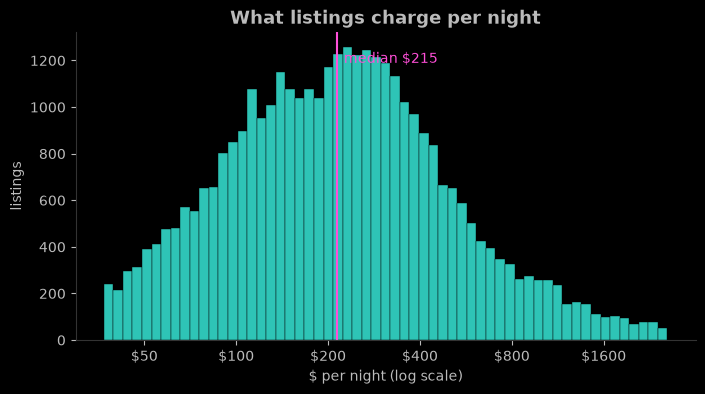

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(np.log10(df.price.min()), np.log10(df.price.max()), 60)
ax.hist(df.price, bins=bins, color=TEAL, edgecolor=BG, linewidth=0.3)
ax.set_xscale("log")
ticks = [t for t in [25, 50, 100, 200, 400, 800, 1600] if df.price.min() <= t <= df.price.max()]
ax.set_xticks(ticks, [f"${t}" for t in ticks])
ax.minorticks_off()
med = df.price.median()
ax.axvline(med, color=PINK)
ax.text(med * 1.05, ax.get_ylim()[1] * 0.9, f"median ${med:,.0f}", color=PINK)
ax.set_title("What listings charge per night")
ax.set_xlabel("$ per night (log scale)")
ax.set_ylabel("listings")
plt.show()